# 軸対称ストリーマの計算格子

左は計算領域全体、右は針先近傍の拡大です。色は本体の気体・電極マスク、細線は拡大範囲内のセル境界、橙色の破線はマスクの元になった解析双曲面を示します。座標は本体と同じで、接地平板が $z=0$ です。

設定セルには実行 Notebook の現行の格子条件を入れています。格子条件を変更したときは、このセルも更新してください。必要なのは格子と形状の設定だけです。

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
import numpy as np

cwd = Path.cwd()
root = next((candidate for base in (cwd, *cwd.parents)
             for candidate in (base, base / "pyaxistreamer-master")
             if (candidate / "streamer_drift_diffusion").is_dir()), None)
if root is None:
    raise FileNotFoundError("PyAxiStreamer のプロジェクト内から実行してください")
sys.path.insert(0, str(root))

from streamer_drift_diffusion import SimulationConfig
from streamer_drift_diffusion.grid import initialize_grid

config = SimulationConfig(
    nr=400, nz=900, delta=20e-6,
    cathode_radius=40e-6, electrode_gap=13e-3,
)
grid_data = initialize_grid(config)
gas = grid_data["gas_mask"]
r_edges = np.r_[grid_data["r"], config.nr * config.delta] * 1e3
z_edges = np.r_[grid_data["z"], config.nz * config.delta] * 1e3
tip = config.electrode_gap * 1e3
spacing_um = config.delta * 1e6

print(f"Grid: {gas.shape[0]} radial × {gas.shape[1]} axial cells, Δ = {spacing_um:g} µm")
print(f"Domain: r = 0–{r_edges[-1]:g} mm, z = 0–{z_edges[-1]:g} mm")
print(f"Tip: z = {tip:g} mm, curvature radius = {config.cathode_radius * 1e6:g} µm")
print(f"Gas cells: {np.count_nonzero(gas):,}; electrode cells: {np.count_nonzero(~gas):,}")

Grid: 400 radial × 900 axial cells, Δ = 20 µm
Domain: r = 0–8 mm, z = 0–18 mm
Tip: z = 13 mm, curvature radius = 40 µm
Gas cells: 354,439; electrode cells: 5,561


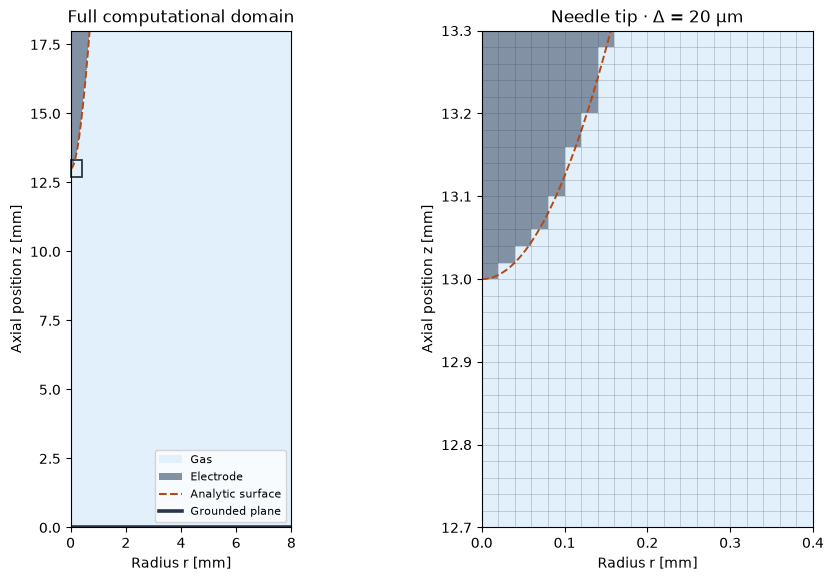

In [2]:
gas_color, electrode_color = "#e1f0fa", "#8391a4"
surface_color = "#b34a17"
cmap = ListedColormap([electrode_color, gas_color])
extent = (r_edges[0], r_edges[-1], z_edges[0], z_edges[-1])

# Keep enough cells in view for different spacings.
zoom_radius = min(r_edges[-1], max(.4, 8 * config.delta * 1e3))
zoom_half_height = max(.3, 6 * config.delta * 1e3)
zoom_z = (max(z_edges[0], tip - zoom_half_height),
          min(z_edges[-1], tip + zoom_half_height))

def draw_mask(ax, radius):
    ax.imshow(gas.T, origin="lower", extent=extent, cmap=cmap,
              vmin=0, vmax=1, interpolation="nearest", aspect="equal")
    r = np.linspace(0., radius, 500)
    z = tip * np.sqrt(1. + (r * 1e-3)**2 /
                      (config.cathode_radius * config.electrode_gap))
    ax.plot(r, z, color=surface_color, lw=1.4, ls="--")
    ax.set(xlabel="Radius r [mm]", ylabel="Axial position z [mm]")

fig, (overview, closeup) = plt.subplots(1, 2, figsize=(9.2, 5.7), layout="constrained")
draw_mask(overview, r_edges[-1])
overview.axhline(0., color="#283749", lw=2.6)
overview.add_patch(Rectangle((0., zoom_z[0]), zoom_radius, zoom_z[1] - zoom_z[0],
                             fill=False, ec="#283749", lw=1.3, clip_on=False))
overview.set(xlim=(0., r_edges[-1]), ylim=(0., z_edges[-1]), title="Full computational domain")
overview.legend(handles=[
    Patch(facecolor=gas_color, label="Gas"),
    Patch(facecolor=electrode_color, label="Electrode"),
    Line2D([], [], color=surface_color, ls="--", label="Analytic surface"),
    Line2D([], [], color="#283749", lw=2.6, label="Grounded plane"),
], loc="lower right", fontsize=8)

draw_mask(closeup, zoom_radius)
r_lines = r_edges[(r_edges >= 0.) & (r_edges <= zoom_radius)]
z_lines = z_edges[(z_edges >= zoom_z[0]) & (z_edges <= zoom_z[1])]
closeup.vlines(r_lines, *zoom_z, color="#283749", alpha=.26, lw=.55)
closeup.hlines(z_lines, 0., zoom_radius, color="#283749", alpha=.26, lw=.55)
closeup.set(xlim=(0., zoom_radius), ylim=zoom_z,
            title=f"Needle tip · Δ = {spacing_um:g} µm")
closeup.ticklabel_format(useOffset=False, axis="y")
plt.show()